# 13 — Final unified detector: Real / Full AI / Partial AI + heatmap mask + AI-area %

One U-Net answers, for every pixel, "is this pixel AI-generated?" — trained on all three classes:

| Class | Images | Pixel target |
|---|---|---|
| Real | COCO photos **+ the untouched originals of the edited photos** | 0 everywhere |
| Full AI | DiffusionDB | 1 everywhere |
| Partial AI | Flux-edited photos with a **verified** mask (08 audit) | 1 inside the mask, 0 elsewhere |

* **Localization** = the heatmap / thresholded mask.
* **Classification** = a small logistic model on 12 statistics of the heatmap (fitted on validation only).
* **Quantification** = Real 0 %, Full AI 100 %, Partial AI = predicted mask area (threshold tuned on validation).

Design decisions (each fixes a problem found earlier in the project):
1. Real photos and Full-AI images are in localization training → the heatmap itself separates the classes.
2. **Paired training**: each edited photo's untouched original is a Real example → the model must learn the edit, not the photo.
3. Random JPEG re-saving and re-scaling for **all** classes → no file-format / resolution shortcut.
4. Split by **source photo** (same split as 06/07) → no leakage; COCO photos that are also edited sources follow that split.
5. Only audited masks are used for pixel supervision; Dice loss only on Partial-AI crops so small edits are not drowned by Full-AI pixels.
6. Starts from your best localization model (`Unet_resnet34_crop512_plusbbox_clean`), same native resolution (≤1024 px).

**Laptop folders needed** (`C:\AI_Image_Project`): `COCO_5000/`, `DiffusionDB_5000/`, `Partial_AI_5000/` (Manipulated, Masks, Original, pairs.csv),
`features/` (y_labels_15k, image_paths_15k, train/val/test_idx), `features/localization/` (train/val/test_idx, mask_audit.csv),
`saved_models/localization/Unet_resnet34_crop512_plusbbox_clean_best.pth`. Cell 2 lists anything missing before any training starts.

In [9]:
# ============================================================
# 1. Setup + configuration
# ============================================================
import os, sys, io, json, math, time, random, pickle, subprocess, importlib, warnings
from pathlib import Path
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    from google.colab import drive; drive.mount("/content/drive")
def ensure(module, pip_name=None):
    try: __import__(module)
    except ImportError: subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", pip_name or module])
ensure("segmentation_models_pytorch", "segmentation-models-pytorch")
import numpy as np, pandas as pd, torch, torch.nn.functional as F, matplotlib.pyplot as plt
import segmentation_models_pytorch as smp
from PIL import Image, ImageFilter, ImageOps
from tqdm.auto import tqdm
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, classification_report
warnings.filterwarnings("ignore"); Image.MAX_IMAGE_PIXELS = None
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 20)

PROJECT_DIR = (Path("/content/drive/MyDrive/AI_Image_Project") if IN_COLAB
               else Path(os.environ.get("AI_PROJECT_DIR", r"C:\AI_Image_Project")))   # <- laptop folder
BASE_DIR = PROJECT_DIR / "Partial_AI_5000"
FEATURES_DIR, LOC_FEATURES_DIR = PROJECT_DIR / "features", PROJECT_DIR / "features" / "localization"
LOC_MODELS_DIR = PROJECT_DIR / "saved_models" / "localization"; LOC_MODELS_DIR.mkdir(parents=True, exist_ok=True)
OUT_DIR = PROJECT_DIR / "results" / "unified"; OUT_DIR.mkdir(parents=True, exist_ok=True)

CFG = dict(
    SEED=42,
    MAX_SIDE=1024,              # longest side cap (all images); Partial AI stays at native resolution like notebook 07
    CROP=384,                   # training crop
    SCALE_PROB=0.5, SCALE_RANGE=(0.6, 1.0),   # half of the crops are randomly down-scaled (all classes)
    JPEG_PROB=0.5, JPEG_Q=(60, 95),           # half of the crops are re-saved as JPEG (all classes)
    POS_CROP_PROB=0.7,          # Partial AI crops centred on the edit
    KIND_SHARE={"coco": 1/6, "original": 1/6, "diffusiondb": 1/3, "partial": 1/3},   # sampling share per source
    ARCH="Unet", ENCODER="resnet34",
    INIT_FROM="Unet_resnet34_crop512_plusbbox_clean",
    EPOCHS=40, SAMPLES_PER_EPOCH=3000,
    LR=2e-4, WEIGHT_DECAY=1e-4, PATIENCE=5,
    VAL_PER_CLASS=150,          # images per class for the quick per-epoch check (full val/test at the end)
    TTA=True,
    MAX_TRAIN_MINUTES=150 if IN_COLAB else None,
)
if torch.cuda.is_available():
    vram = torch.cuda.get_device_properties(0).total_memory / 1e9
    CFG["BATCH_SIZE"] = 16 if vram >= 14 else 8
else:
    CFG["BATCH_SIZE"] = 4
CFG["NUM_WORKERS"] = 2 if IN_COLAB else min(4, os.cpu_count() or 2)   # Windows: set to 0 if cell 3 reports a worker error
RUN = f'unified_{CFG["ARCH"]}_{CFG["ENCODER"]}_crop{CFG["CROP"]}'
BEST, LAST = LOC_MODELS_DIR / f"{RUN}_best.pth", LOC_MODELS_DIR / f"{RUN}_last.pth"
DEPLOY = LOC_MODELS_DIR / f"{RUN}_deploy.pkl"
device = torch.device("cuda" if torch.cuda.is_available() else "cpu"); USE_AMP = device.type == "cuda"
random.seed(CFG["SEED"]); np.random.seed(CFG["SEED"]); torch.manual_seed(CFG["SEED"])
CLASS_NAMES = ["Real", "Full AI", "Partial AI"]
print("Device:", device, torch.cuda.get_device_name(0) if USE_AMP else "", "| run:", RUN, "| batch", CFG["BATCH_SIZE"])

Device: cuda NVIDIA GeForce RTX 4050 Laptop GPU | run: unified_Unet_resnet34_crop384 | batch 8


In [10]:
# ============================================================
# 2. Check files, then build one table of all images: path, class, verified mask, split by source photo
# ============================================================
need = {"pairs.csv": BASE_DIR / "pairs.csv", "mask_audit.csv": LOC_FEATURES_DIR / "mask_audit.csv",
        "localization split": LOC_FEATURES_DIR / "test_idx.npy", "image_paths_15k.npy": FEATURES_DIR / "image_paths_15k.npy",
        "y_labels_15k.npy": FEATURES_DIR / "y_labels_15k.npy", "15k split": FEATURES_DIR / "test_idx.npy",
        "init model": LOC_MODELS_DIR / f'{CFG["INIT_FROM"]}_best.pth',
        "COCO_5000/": PROJECT_DIR / "COCO_5000", "DiffusionDB_5000/": PROJECT_DIR / "DiffusionDB_5000",
        "Original/": BASE_DIR / "Original", "Manipulated/": BASE_DIR / "Manipulated", "Masks/": BASE_DIR / "Masks"}
missing = [k for k, p in need.items() if not p.exists()]
assert not missing, "Missing (download from Drive into the same place under " + str(PROJECT_DIR) + "): " + ", ".join(missing)

pairs = pd.read_csv(BASE_DIR / "pairs.csv"); pairs["pairs_row"] = np.arange(len(pairs))
audit = pd.read_csv(LOC_FEATURES_DIR / "mask_audit.csv").set_index("row")
a = audit.loc[pairs["pairs_row"].to_numpy()]
use_csv = (a["verdict"] == "ok").to_numpy()
use_alt = ((~use_csv) & (a["alt_verdict"] == "ok").to_numpy()) if "alt_verdict" in a else np.zeros(len(a), bool)
alt_paths = a["alt_mask_path"].astype(str).to_numpy() if "alt_mask_path" in a else pairs["mask_path"].to_numpy()
pairs["verified_mask"] = np.where(use_csv, pairs["mask_path"], np.where(use_alt, alt_paths, ""))

segm = pairs[pairs.mask_type == "segm"].reset_index(drop=True)
SRC_SPLIT = {}
for name in ("val", "test"):
    for s in segm["source_id"].to_numpy()[np.load(LOC_FEATURES_DIR / f"{name}_idx.npy")]:
        SRC_SPLIT[int(s)] = name
src_split = lambda s: SRC_SPLIT.get(int(s), "train")

rows = []
for r in pairs.itertuples():                                       # Partial AI
    rows.append(dict(path=str(BASE_DIR / r.manipulated_path), label=2, kind="partial", mtype=r.mask_type,
                     mask=str(BASE_DIR / r.verified_mask) if r.verified_mask else "", split=src_split(r.source_id)))
for op, s in pairs.groupby("original_path")["source_id"].first().items():   # untouched originals -> Real
    rows.append(dict(path=str(BASE_DIR / op), label=0, kind="original", mtype="", mask="", split=src_split(s)))
paths15 = np.load(FEATURES_DIR / "image_paths_15k.npy", allow_pickle=True); y15 = np.load(FEATURES_DIR / "y_labels_15k.npy")
split15 = np.empty(len(y15), dtype=object)
for name in ("train", "val", "test"): split15[np.load(FEATURES_DIR / f"{name}_idx.npy")] = name
def local(p):
    p = str(p).replace("\\", "/"); k = "AI_Image_Project/"
    return str(PROJECT_DIR / p.split(k, 1)[1]) if k in p else p
for i in np.where(y15 <= 1)[0]:                                    # COCO (Real) + DiffusionDB (Full AI), notebook-01 split
    p = local(paths15[i]); stem = Path(p).stem; sp = split15[i]
    if y15[i] == 0 and stem.isdigit() and int(stem) in SRC_SPLIT:  # COCO photo that is also an edited source
        sp = SRC_SPLIT[int(stem)]
    rows.append(dict(path=p, label=int(y15[i]), kind="coco" if y15[i] == 0 else "diffusiondb", mtype="", mask="", split=sp))

DF = pd.DataFrame(rows)
ex = DF["path"].map(lambda p: Path(p).exists())
if (~ex).any():
    print("Image files not found (by source):", DF[~ex].groupby("kind").size().to_dict())
    assert ex.groupby(DF.kind).mean().min() > 0.9, "A whole folder seems missing - check the paths above"
DF = DF[ex].reset_index(drop=True)
DF["has_mask"] = DF["mask"] != ""
print(pd.crosstab([DF.kind, DF.label], DF.split, margins=True).to_string())
print("\nPartial AI images with an audited mask:", int((DF.label.eq(2) & DF.has_mask).sum()), "of", int(DF.label.eq(2).sum()))

split              test  train   val    All
kind        label                          
coco        0       589   3817   594   5000
diffusiondb 1       500   4000   500   5000
original    0       113   1333   112   1558
partial     2       429   4073   498   5000
All                1631  13223  1704  16558

Partial AI images with an audited mask: 2639 of 5000


In [11]:
# ============================================================
# 3. Data loading -> small module file so DataLoader workers also work on Windows
# ============================================================
MODULE = r"""
import io, random
import numpy as np, torch
from PIL import Image
Image.MAX_IMAGE_PIXELS = None
IGNORE = 255

def load_resized(path, max_side):
    im = Image.open(path).convert("RGB")
    s = min(1.0, max_side / max(im.size))
    if s < 1: im = im.resize((max(1, round(im.size[0] * s)), max(1, round(im.size[1] * s))), Image.Resampling.BICUBIC)
    return im

def target_mask(label, mask_path, size):
    w, h = size
    if label == 0: return np.zeros((h, w), np.uint8)
    if label == 1: return np.ones((h, w), np.uint8)
    m = Image.open(mask_path).convert("L")
    if m.size != size: m = m.resize(size, Image.Resampling.NEAREST)
    return (np.asarray(m) > 127).astype(np.uint8)

def jpeg(img, q):
    b = io.BytesIO(); img.save(b, "JPEG", quality=int(q)); b.seek(0); return Image.open(b).convert("RGB")

class TrainSet(torch.utils.data.Dataset):
    def __init__(self, items, cfg): self.items, self.c = items, cfg
    def __len__(self): return len(self.items)
    def __getitem__(self, k):
        for _ in range(10):                       # a corrupt file never stops training: try another image
            try: return self._get(k)
            except Exception: k = random.randrange(len(self.items))
        raise RuntimeError("10 unreadable images in a row - check the dataset folders")
    def _get(self, k):
        path, label, mpath = self.items[k]; c = self.c; crop = c["CROP"]
        img = load_resized(path, c["MAX_SIDE"])
        if random.random() < c["SCALE_PROB"]:
            s = random.uniform(*c["SCALE_RANGE"])
            img = img.resize((max(1, round(img.size[0] * s)), max(1, round(img.size[1] * s))), Image.Resampling.BICUBIC)
        m = target_mask(label, mpath, img.size)
        a = np.asarray(img); H, W = m.shape
        if H < crop or W < crop:                 # pad; padded pixels are ignored by the loss
            ph, pw = max(0, crop - H), max(0, crop - W)
            a = np.pad(a, ((0, ph), (0, pw), (0, 0)))
            m = np.pad(m, ((0, ph), (0, pw)), constant_values=IGNORE); H, W = m.shape
        if label == 2 and random.random() < c["POS_CROP_PROB"] and (m == 1).any():
            ys, xs = np.nonzero(m == 1); j = random.randrange(len(ys)); y, x = ys[j], xs[j]
            y0 = int(np.clip(y - random.randrange(crop), 0, H - crop)); x0 = int(np.clip(x - random.randrange(crop), 0, W - crop))
        else:
            y0, x0 = random.randint(0, H - crop), random.randint(0, W - crop)
        a = a[y0:y0 + crop, x0:x0 + crop]; m = m[y0:y0 + crop, x0:x0 + crop]
        if random.random() < 0.5: a, m = a[:, ::-1], m[:, ::-1]
        if random.random() < c["JPEG_PROB"]:
            a = np.asarray(jpeg(Image.fromarray(np.ascontiguousarray(a)), random.randint(*c["JPEG_Q"])))
        return (torch.from_numpy(np.ascontiguousarray(a).transpose(2, 0, 1).copy()),
                torch.from_numpy(np.ascontiguousarray(m).copy()), torch.tensor(label))

def worker_init(i):
    s = torch.initial_seed() % 2**32; random.seed(s + i); np.random.seed((s + i) % 2**32)
"""
Path("unified_ds.py").write_text(MODULE)
if str(Path.cwd()) not in sys.path: sys.path.insert(0, str(Path.cwd()))
import unified_ds; importlib.reload(unified_ds)

train_df = DF[(DF.split == "train") & ((DF.label != 2) | DF.has_mask)].reset_index(drop=True)
items = list(zip(train_df.path, train_df.label, train_df["mask"]))
share = train_df.kind.map(CFG["KIND_SHARE"]); counts = train_df.kind.map(train_df.kind.value_counts())
sampler = torch.utils.data.WeightedRandomSampler(torch.tensor((share / counts).to_numpy(), dtype=torch.double),
                                                 CFG["SAMPLES_PER_EPOCH"], replacement=True)
train_loader = torch.utils.data.DataLoader(unified_ds.TrainSet(items, CFG), batch_size=CFG["BATCH_SIZE"], sampler=sampler,
                                           num_workers=CFG["NUM_WORKERS"], pin_memory=USE_AMP, drop_last=True,
                                           persistent_workers=CFG["NUM_WORKERS"] > 0, worker_init_fn=unified_ds.worker_init)
print("Training images:", train_df.kind.value_counts().to_dict())
t0 = time.time(); xb, yb, lb = next(iter(train_loader))
print(f"First batch OK in {time.time()-t0:.1f}s:", tuple(xb.shape), "| classes", lb.tolist())

Training images: {'diffusiondb': 4000, 'coco': 3817, 'partial': 2139, 'original': 1333}
First batch OK in 13.1s: (8, 3, 384, 384) | classes [2, 2, 2, 0, 0, 1, 1, 2]


In [12]:
# ============================================================
# 4. Model, loss, full-image prediction, heatmap statistics, evaluation
# ============================================================
MEAN = torch.tensor([0.485, 0.456, 0.406], device=device).view(1, 3, 1, 1) * 255
STD  = torch.tensor([0.229, 0.224, 0.225], device=device).view(1, 3, 1, 1) * 255
THRS = np.round(np.r_[0.01, 0.02, 0.03, 0.04, np.arange(0.05, 0.951, 0.05)], 2)
STAT_NAMES = ["frac>0.1", "frac>0.3", "frac>0.5", "frac>0.7", "frac>0.9", "mean", "std", "max", "p99", "p95", "p50", "top1%mean"]

def make_model(weights=None):
    return smp.create_model(arch=CFG["ARCH"], encoder_name=CFG["ENCODER"], encoder_weights=weights, in_channels=3,
                            classes=1).to(device).to(memory_format=torch.channels_last)

def norm(x):
    return ((x.to(device, non_blocking=True).float() - MEAN) / STD).contiguous(memory_format=torch.channels_last)

def unified_loss(logits, target, labels):
    # BCE on every valid pixel (Real -> 0, Full AI -> 1, Partial AI -> mask) + soft Dice on Partial-AI crops only
    logits = logits.float(); valid = (target != 255).float(); t = (target == 1).float()
    bce = (F.binary_cross_entropy_with_logits(logits, t, reduction="none") * valid).sum() / valid.sum().clamp(min=1)
    part = (labels == 2).view(-1, 1, 1, 1).float() * valid
    if part.sum() == 0: return bce
    p = torch.sigmoid(logits)
    dice = (2 * (p * t * part).sum() + 1) / ((p * part).sum() + (t * part).sum() + 1)
    return bce + (1 - dice)

@torch.no_grad()
def predict_prob(model, img_arr, tta=False):
    H, W = img_arr.shape[:2]
    x = norm(torch.from_numpy(np.array(img_arr)).permute(2, 0, 1)[None])
    x = F.pad(x, (0, (-W) % 32, 0, (-H) % 32), mode="reflect")
    with torch.autocast(device.type, dtype=torch.float16, enabled=USE_AMP):
        p = torch.sigmoid(model(x).float())
        if tta: p = 0.5 * (p + torch.sigmoid(model(x.flip(-1)).float()).flip(-1))
    return p[0, 0, :H, :W].float()

def image_stats(p):
    f = p.flatten(); k = max(1, int(0.01 * f.numel()))
    q = torch.quantile(f[:: max(1, f.numel() // 200000)], torch.tensor([0.99, 0.95, 0.5], device=f.device))
    return np.array([(f > t).float().mean().item() for t in (0.1, 0.3, 0.5, 0.7, 0.9)] +
                    [f.mean().item(), f.std().item(), f.max().item()] + q.tolist() + [f.topk(k).values.mean().item()], np.float32)

@torch.no_grad()
def run_eval(model, df, tta=False, desc="eval"):
    # one pass: heatmap statistics for every image; pixel counts at every threshold for Partial AI with an audited mask
    model.eval(); torch.backends.cudnn.benchmark = False
    thr = torch.tensor(THRS, device=device, dtype=torch.float32).view(-1, 1, 1)
    keep, S, inter, pred, gt, npx, fracs = [], [], [], [], [], [], []
    for j, r in enumerate(tqdm(df.itertuples(), total=len(df), desc=desc, leave=False)):
        try:
            img = unified_ds.load_resized(r.path, CFG["MAX_SIDE"])
        except Exception:
            continue                                   # unreadable image: skipped (counted below)
        p = predict_prob(model, np.asarray(img), tta)
        keep.append(j); S.append(image_stats(p)); npx.append(p.numel())
        fracs.append((p.unsqueeze(0) >= thr).float().mean((1, 2)).cpu().numpy())      # predicted area at every threshold
        if r.label == 2 and r.has_mask:
            g = torch.from_numpy(unified_ds.target_mask(2, r.mask, img.size)).to(device).bool(); pr = p.unsqueeze(0) >= thr
            inter.append((pr & g).sum((1, 2)).cpu().numpy()); pred.append(pr.sum((1, 2)).cpu().numpy()); gt.append(g.sum().item())
        else:
            inter.append(None); pred.append(None); gt.append(None)
    torch.backends.cudnn.benchmark = True
    if len(keep) < len(df): print(f"  ({len(df) - len(keep)} unreadable images skipped)")
    sub = df.iloc[keep].reset_index(drop=True)
    return dict(df=sub, stats=np.stack(S), label=sub.label.to_numpy(), inter=inter, pred=pred, gt=gt,
                npx=np.array(npx, float), fracs=np.stack(fracs))

def pixel_f1(ev, t, only=None):
    k = [i for i, g in enumerate(ev["gt"]) if g is not None and (only is None or ev["df"].mtype[i] == only)]
    if not k: return np.nan, np.nan, 0
    I = np.array([ev["inter"][i][t] for i in k]); P = np.array([ev["pred"][i][t] for i in k]); G = np.array([ev["gt"][i] for i in k])
    return float((2 * I / (P + G + 1e-9)).mean()), float(2 * I.sum() / (P.sum() + G.sum() + 1e-9)), len(k)

def make_clf(): return make_pipeline(StandardScaler(), LogisticRegression(C=1.0, max_iter=3000))
def cv_class_f1(ev):
    n_min = np.bincount(ev["label"], minlength=3).min()
    pred = cross_val_predict(make_clf(), ev["stats"], ev["label"], cv=StratifiedKFold(min(5, max(2, n_min)), shuffle=True, random_state=0))
    return f1_score(ev["label"], pred, average="macro")

model = make_model()
model.load_state_dict(torch.load(LOC_MODELS_DIR / f'{CFG["INIT_FROM"]}_best.pth', map_location=device, weights_only=False)["model"])
print("Initialised from", CFG["INIT_FROM"])

Initialised from Unet_resnet34_crop512_plusbbox_clean


In [13]:
# ============================================================
# 5. Training (balanced sources, AMP, best/last checkpoints, auto-resume, early stopping)
# ============================================================
val_all = DF[DF.split == "val"].reset_index(drop=True)
val_quick = pd.concat([d.sample(min(len(d), CFG["VAL_PER_CLASS"]), random_state=0) for _, d in val_all.groupby("label")]).reset_index(drop=True)
opt = torch.optim.AdamW(model.parameters(), lr=CFG["LR"], weight_decay=CFG["WEIGHT_DECAY"])
steps = len(train_loader); total = CFG["EPOCHS"] * steps
sched = torch.optim.lr_scheduler.LambdaLR(opt, lambda s: min(1.0, (s + 1) / steps) * (0.02 + 0.98 * 0.5 * (1 + math.cos(math.pi * min(1.0, s / total)))))
scaler = torch.amp.GradScaler(device.type, enabled=USE_AMP)
start, best, bad, hist = 0, -1.0, 0, []
if LAST.exists():
    ck = torch.load(LAST, map_location=device, weights_only=False)
    model.load_state_dict(ck["model"]); opt.load_state_dict(ck["opt"]); sched.load_state_dict(ck["sched"]); scaler.load_state_dict(ck["scaler"])
    start, best, bad, hist = ck["epoch"], ck["best"], ck["bad"], ck["hist"]; print(f"Resumed after epoch {start}")

torch.backends.cudnn.benchmark = True; t_start = time.time()
for ep in range(start, CFG["EPOCHS"]):
    if bad >= CFG["PATIENCE"]: print("Early stopping."); break
    if CFG["MAX_TRAIN_MINUTES"] and (time.time() - t_start) / 60 > CFG["MAX_TRAIN_MINUTES"]:
        print("Time budget reached - evaluating the best model so far (re-run later to continue)."); break
    model.train(); t0 = time.time(); tot = 0.0
    for x, y, lab in tqdm(train_loader, desc=f"Epoch {ep+1}/{CFG['EPOCHS']}", leave=False):
        y = y.to(device, non_blocking=True).unsqueeze(1); lab = lab.to(device)
        opt.zero_grad(set_to_none=True)
        with torch.autocast(device.type, dtype=torch.float16, enabled=USE_AMP):
            logits = model(norm(x))
        loss = unified_loss(logits, y, lab)
        scaler.scale(loss).backward(); scaler.unscale_(opt); torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        scaler.step(opt); scaler.update(); sched.step(); tot += loss.item()
    ev = run_eval(model, val_quick, desc="val")
    cls_f1 = cv_class_f1(ev); pf1 = np.nanmax([pixel_f1(ev, t)[0] for t in range(len(THRS))])
    score = 0.5 * cls_f1 + 0.5 * pf1
    hist.append(dict(epoch=ep + 1, loss=tot / steps, val_class_macroF1=cls_f1, val_partial_pixelF1=pf1, score=score, minutes=(time.time() - t0) / 60))
    improved = score > best
    if improved: best, bad = score, 0; torch.save({"model": model.state_dict(), "cfg": CFG, "epoch": ep + 1}, BEST)
    else: bad += 1
    torch.save({"model": model.state_dict(), "opt": opt.state_dict(), "sched": sched.state_dict(), "scaler": scaler.state_dict(),
                "epoch": ep + 1, "best": best, "bad": bad, "hist": hist}, LAST)
    print(f"Ep {ep+1:02d} | loss {tot/steps:.4f} | val class macro-F1 {cls_f1:.4f} | partial pixel F1 {pf1:.4f} | "
          f"score {score:.4f} | {(time.time()-t0)/60:.1f} min" + ("  *best*" if improved else ""))
pd.DataFrame(hist).to_csv(OUT_DIR / f"{RUN}_history.csv", index=False)

Resumed after epoch 20


Epoch 21/40:   0%|          | 0/375 [00:00<?, ?it/s]

val:   0%|          | 0/450 [00:00<?, ?it/s]

Ep 21 | loss 0.4120 | val class macro-F1 0.8641 | partial pixel F1 0.4390 | score 0.6516 | 2.4 min


Epoch 22/40:   0%|          | 0/375 [00:00<?, ?it/s]

val:   0%|          | 0/450 [00:00<?, ?it/s]

... (6 outputs left out)

Ep 24 | loss 0.3398 | val class macro-F1 0.8322 | partial pixel F1 0.4309 | score 0.6316 | 2.4 min


Epoch 25/40:   0%|          | 0/375 [00:00<?, ?it/s]

val:   0%|          | 0/450 [00:00<?, ?it/s]

Ep 25 | loss 0.3658 | val class macro-F1 0.8374 | partial pixel F1 0.4159 | score 0.6266 | 2.3 min
Early stopping.


Validation (all):   0%|          | 0/1704 [00:00<?, ?it/s]

Test (all):   0%|          | 0/1631 [00:00<?, ?it/s]

CLASSIFICATION (test)
Accuracy 0.8510 | macro-F1 0.8406
              precision    recall  f1-score   support

        Real     0.7882    0.8960    0.8387       702
     Full AI     0.9960    0.9900    0.9930       500
  Partial AI     0.7857    0.6154    0.6902       429

    accuracy                         0.8510      1631
   macro avg     0.8566    0.8338    0.8406      1631
weighted avg     0.8513    0.8510    0.8469      1631

Accuracy by image source:
  coco         0.927  (n=589)
  original     0.735  (n=113)
  diffusiondb  0.990  (n=500)
  partial      0.615  (n=429)

LOCALIZATION (test Partial AI with audited masks, threshold 0.2 chosen on validation)
All audited masks : mean F1 per image 0.4417 | overall F1 0.4516 | n=260
segm masks only   : mean F1 per image 0.3878 | overall F1 0.4112 | n=141  (same images as notebook 07)

QUANTIFICATION (AI-area %, area threshold 0.55 chosen on validation)
All test images with a known true area: MAE 1.23 pp (n=1462)
Partial AI (end-to-end,

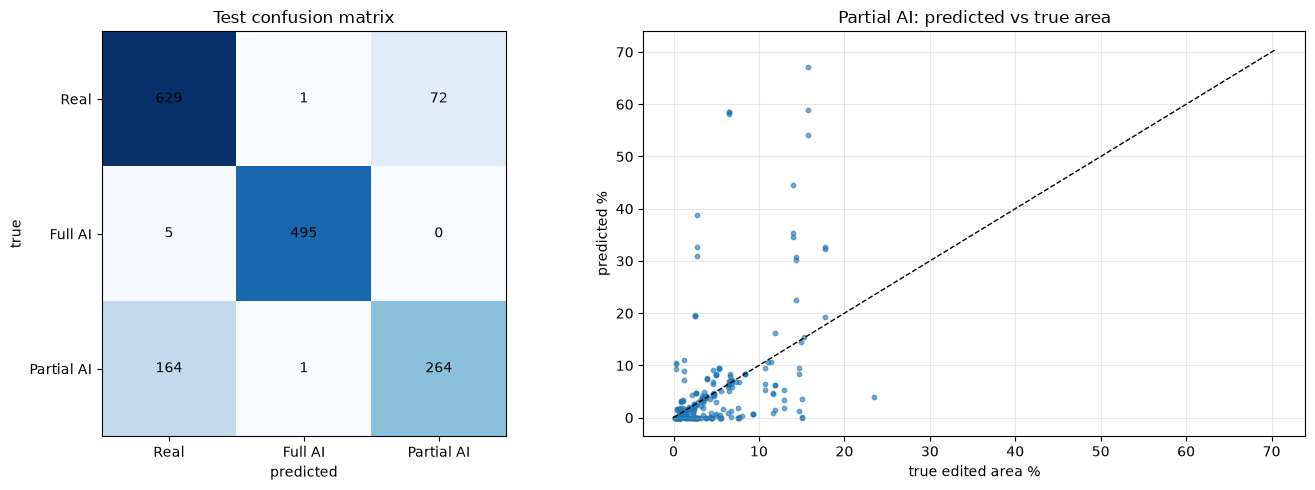


Saved: unified_Unet_resnet34_crop384_best.pth unified_Unet_resnet34_crop384_deploy.pkl and results in C:\AI_Image_Project\results\unified


In [14]:
# ============================================================
# 6. Final evaluation: decision rules fitted on VALIDATION, everything reported on TEST
# ============================================================
model = make_model(); model.load_state_dict(torch.load(BEST, map_location=device, weights_only=False)["model"]); model.eval()
ev_val = run_eval(model, val_all, tta=CFG["TTA"], desc="Validation (all)")
ev_test = run_eval(model, DF[DF.split == "test"].reset_index(drop=True), tta=CFG["TTA"], desc="Test (all)")

# (a) classification from heatmap statistics
CLF = make_clf().fit(ev_val["stats"], ev_val["label"])
pt = CLF.predict_proba(ev_test["stats"]); yt = ev_test["label"]; yp = pt.argmax(1); kinds = ev_test["df"].kind.to_numpy()
# (b) mask threshold (best mean per-image F1) and area threshold (lowest area error) on validation Partial AI
T = int(np.nanargmax([pixel_f1(ev_val, t)[0] for t in range(len(THRS))])); THR = float(THRS[T])
vk = [i for i, g in enumerate(ev_val["gt"]) if g is not None]
true_val = np.array([100 * ev_val["gt"][i] / ev_val["npx"][i] for i in vk])
T_AREA = int(np.argmin([np.abs(100 * ev_val["fracs"][vk, t] - true_val).mean() for t in range(len(THRS))])); AREA_THR = float(THRS[T_AREA])

print("=" * 70); print("CLASSIFICATION (test)"); print("=" * 70)
print(f"Accuracy {accuracy_score(yt, yp):.4f} | macro-F1 {f1_score(yt, yp, average='macro'):.4f}")
print(classification_report(yt, yp, target_names=CLASS_NAMES, digits=4))
print("Accuracy by image source:")
for k in ["coco", "original", "diffusiondb", "partial"]:
    if (kinds == k).any(): print(f"  {k:12s} {accuracy_score(yt[kinds == k], yp[kinds == k]):.3f}  (n={int((kinds == k).sum())})")

print("\n" + "=" * 70); print(f"LOCALIZATION (test Partial AI with audited masks, threshold {THR} chosen on validation)"); print("=" * 70)
f_all = pixel_f1(ev_test, T); f_segm = pixel_f1(ev_test, T, "segm")
print(f"All audited masks : mean F1 per image {f_all[0]:.4f} | overall F1 {f_all[1]:.4f} | n={f_all[2]}")
print(f"segm masks only   : mean F1 per image {f_segm[0]:.4f} | overall F1 {f_segm[1]:.4f} | n={f_segm[2]}  (same images as notebook 07)")

print("\n" + "=" * 70); print(f"QUANTIFICATION (AI-area %, area threshold {AREA_THR} chosen on validation)"); print("=" * 70)
part_area = 100 * ev_test["fracs"][:, T_AREA]
pred_area = np.where(yp == 0, 0.0, np.where(yp == 1, 100.0, part_area))
true_area = np.array([0.0 if l == 0 else 100.0 if l == 1 else (100 * ev_test["gt"][i] / ev_test["npx"][i] if ev_test["gt"][i] is not None else np.nan)
                      for i, l in enumerate(yt)])
ok = ~np.isnan(true_area); m2 = ok & (yt == 2)
err = np.abs(pred_area - true_area)
print(f"All test images with a known true area: MAE {err[ok].mean():.2f} pp (n={ok.sum()})")
print(f"Partial AI (end-to-end, includes classification errors): MAE {err[m2].mean():.2f} pp | median {np.median(err[m2]):.2f} pp")
e_loc = np.abs(part_area - true_area)[m2]
print(f"Partial AI (mask area only):                           MAE {e_loc.mean():.2f} pp | median {np.median(e_loc):.2f} pp | within 2 pp {100*(e_loc <= 2).mean():.0f}%")

print("\n" + "=" * 70); print("COMPARISON WITH THE EARLIER SYSTEM (notebooks 07 + 09)"); print("=" * 70)
comp = pd.DataFrame([
    ["Real (COCO) accuracy", 0.768, accuracy_score(yt[kinds == "coco"], yp[kinds == "coco"]) if (kinds == "coco").any() else np.nan, "same COCO test images"],
    ["Full AI accuracy", 0.980, accuracy_score(yt[kinds == "diffusiondb"], yp[kinds == "diffusiondb"]) if (kinds == "diffusiondb").any() else np.nan, "same DiffusionDB test images"],
    ["Partial AI accuracy", 0.788, accuracy_score(yt[kinds == "partial"], yp[kinds == "partial"]) if (kinds == "partial").any() else np.nan, "earlier test had leakage (random split)"],
    ["Localization overall F1 (segm)", 0.729, f_segm[1], "same audited segm test images"],
    ["Localization mean F1 per image (segm)", 0.547, f_segm[0], "same audited segm test images"],
], columns=["metric", "earlier (07 + 09)", "unified (this)", "note"])
print(comp.round(3).to_string(index=False))

cm = confusion_matrix(yt, yp, labels=range(3))
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
ax[0].imshow(cm, cmap="Blues"); ax[0].set_xticks(range(3), CLASS_NAMES); ax[0].set_yticks(range(3), CLASS_NAMES)
for (r_, c_), v in np.ndenumerate(cm): ax[0].text(c_, r_, v, ha="center", va="center")
ax[0].set_xlabel("predicted"); ax[0].set_ylabel("true"); ax[0].set_title("Test confusion matrix")
mm = m2
ax[1].scatter(true_area[mm], part_area[mm], s=10, alpha=.6); mx = max(np.nanmax(true_area[mm]), part_area[mm].max()) * 1.05
ax[1].plot([0, mx], [0, mx], "k--", lw=1); ax[1].set_xlabel("true edited area %"); ax[1].set_ylabel("predicted %")
ax[1].set_title("Partial AI: predicted vs true area"); ax[1].grid(alpha=.3)
plt.tight_layout(); plt.savefig(OUT_DIR / f"{RUN}_test_summary.png", dpi=110); plt.show()

with open(DEPLOY, "wb") as f:
    pickle.dump({"cfg": CFG, "mask_threshold": THR, "area_threshold": AREA_THR, "classifier": CLF, "stat_names": STAT_NAMES}, f)
summary = {"test_accuracy": accuracy_score(yt, yp), "test_macro_f1": f1_score(yt, yp, average="macro"),
           "loc_f1_per_image_all": f_all[0], "loc_f1_overall_all": f_all[1], "loc_f1_per_image_segm": f_segm[0], "loc_f1_overall_segm": f_segm[1],
           "area_mae_all": err[ok].mean(), "area_mae_partial_end_to_end": err[m2].mean(), "area_mae_partial_mask_only": e_loc.mean(),
           "mask_threshold": THR, "area_threshold": AREA_THR}
json.dump({k: float(v) for k, v in summary.items()}, open(OUT_DIR / f"{RUN}_summary.json", "w"), indent=2)
comp.to_csv(OUT_DIR / f"{RUN}_comparison.csv", index=False)
print("\nSaved:", BEST.name, DEPLOY.name, "and results in", OUT_DIR)

gopgop.jpeg: Partial AI (58%) | Real 41.8% | Full AI 0.1% | Partial AI 58.1% | AI area = 0.28%


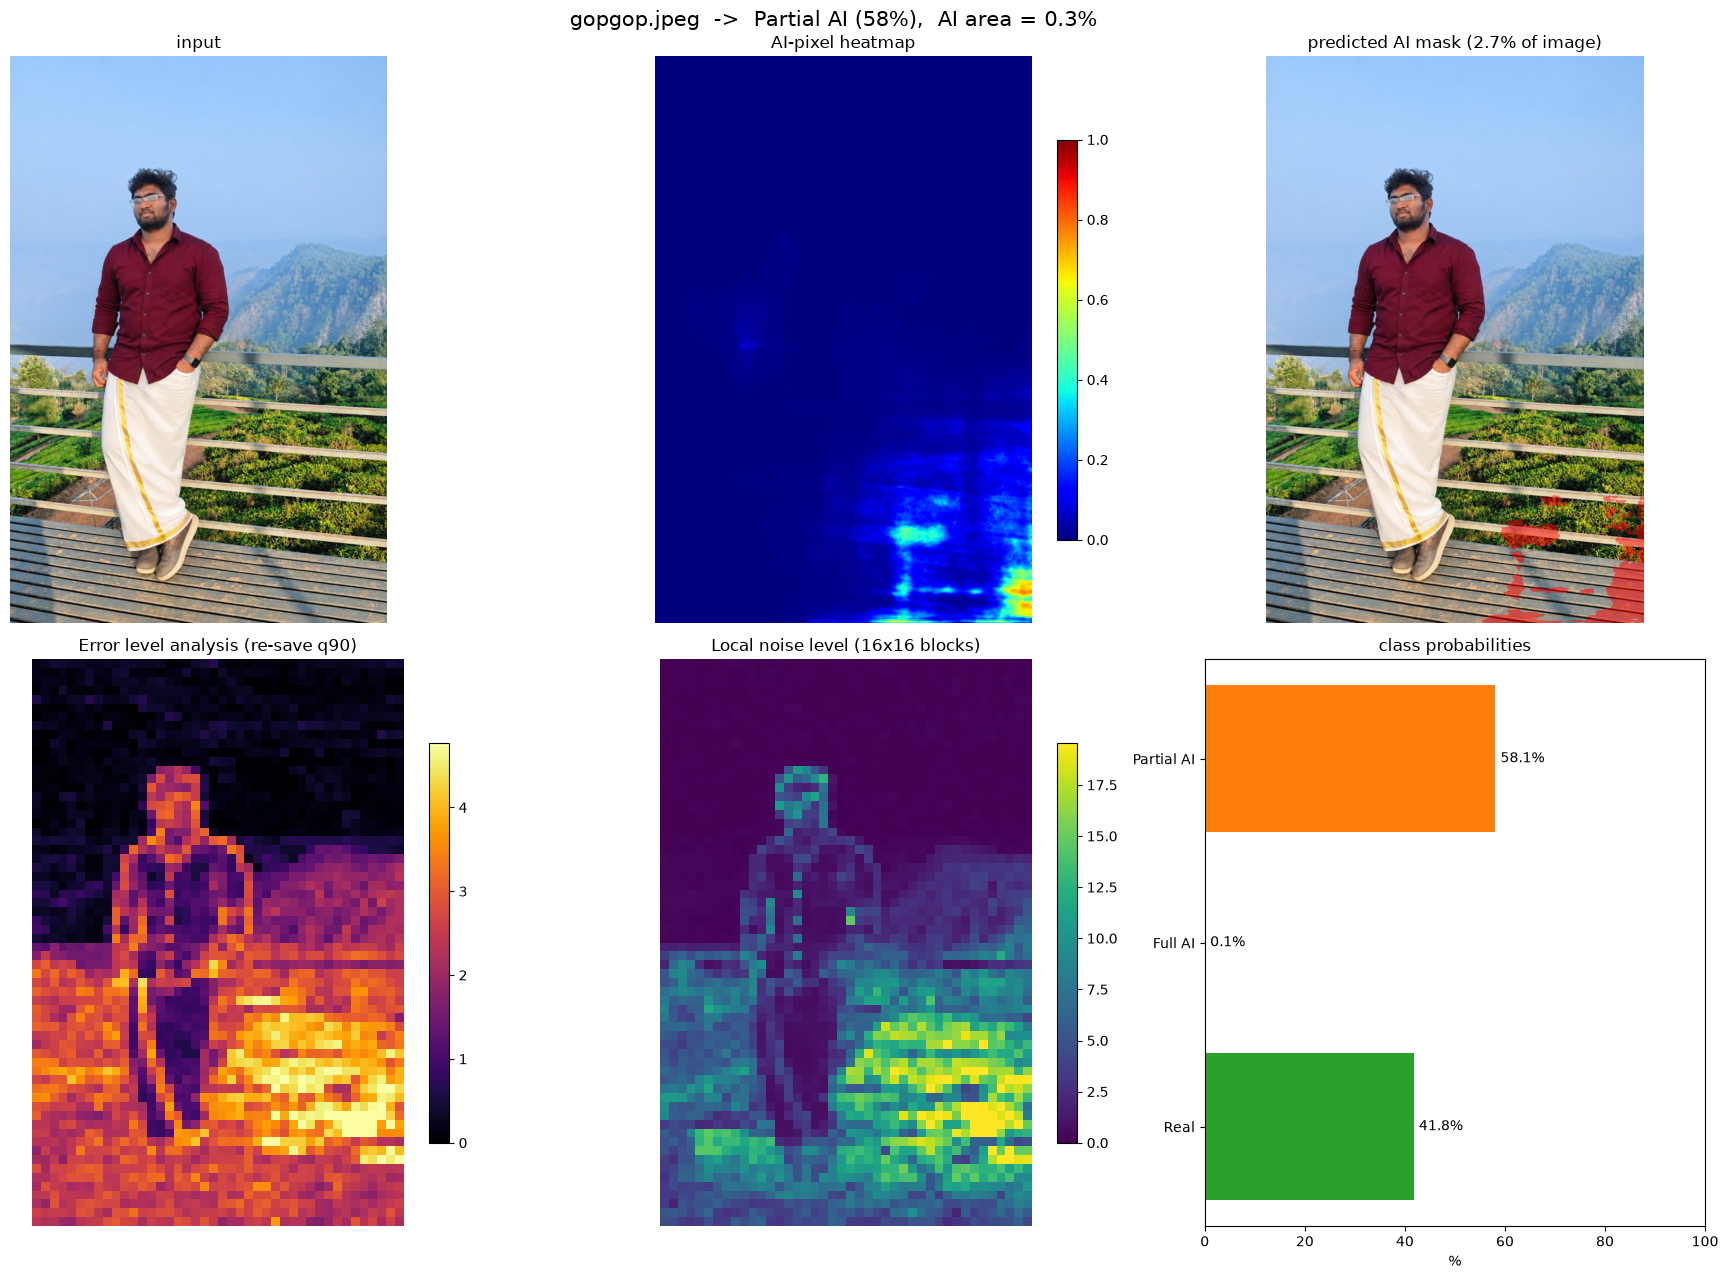

In [18]:
# ============================================================
# 7. Analyse ANY image: class + heatmap + mask + AI-area % + forensic maps (figure saved for the report)
#    Works on its own after a restart: run cells 1, 4 and this one (it loads the saved model).
# ============================================================
if "CLF" not in globals() or "THR" not in globals():
    dep = pickle.load(open(DEPLOY, "rb")); CLF, THR, AREA_THR = dep["classifier"], dep["mask_threshold"], dep["area_threshold"]
    model = make_model(); model.load_state_dict(torch.load(BEST, map_location=device, weights_only=False)["model"]); model.eval()
    import unified_ds
REPORT_DIR = PROJECT_DIR / "results" / "analysis"; REPORT_DIR.mkdir(parents=True, exist_ok=True)

def forensic_maps(img, block=16, quality=90):
    rgb = img.convert("RGB"); a = np.asarray(rgb).astype(np.float32)
    b = io.BytesIO(); rgb.save(b, "JPEG", quality=quality); b.seek(0)
    ela = np.abs(a - np.asarray(Image.open(b).convert("RGB")).astype(np.float32)).mean(2)
    g = rgb.convert("L"); res = np.asarray(g).astype(np.float32) - np.asarray(g.filter(ImageFilter.MedianFilter(3))).astype(np.float32)
    H, W = (ela.shape[0] // block) * block, (ela.shape[1] // block) * block
    blk = lambda m, f: f(m[:H, :W].reshape(H // block, block, W // block, block), axis=(1, 3))
    return blk(ela, np.mean), blk(res, np.std)

def analyze(path, show=True, save=True):
    img = ImageOps.exif_transpose(Image.open(path)).convert("RGB")      # phone photos: upright orientation only
    s = min(1.0, CFG["MAX_SIDE"] / max(img.size))
    if s < 1: img = img.resize((round(img.size[0] * s), round(img.size[1] * s)), Image.Resampling.BICUBIC)
    arr = np.asarray(img); p = predict_prob(model, arr, CFG["TTA"])
    probs = CLF.predict_proba(image_stats(p)[None])[0]; cls = int(np.argmax(probs))
    heat = p.cpu().numpy(); mask = heat >= THR
    area = 0.0 if cls == 0 else 100.0 if cls == 1 else 100 * float((heat >= AREA_THR).mean())
    print(f"{Path(path).name}: {CLASS_NAMES[cls]} ({probs[cls]*100:.0f}%) | " + " | ".join(f"{n} {q*100:.1f}%" for n, q in zip(CLASS_NAMES, probs))
          + f" | AI area = {area:.2f}%")
    if show or save:
        ela, noise = forensic_maps(img)
        ov = arr.copy(); ov[mask] = (0.5 * ov[mask] + [127, 0, 0]).astype(np.uint8)
        fig, ax = plt.subplots(2, 3, figsize=(18, 13))
        ax[0, 0].imshow(arr); ax[0, 0].set_title("input")
        i1 = ax[0, 1].imshow(heat, cmap="jet", vmin=0, vmax=1); ax[0, 1].set_title("AI-pixel heatmap"); plt.colorbar(i1, ax=ax[0, 1], fraction=0.04)
        ax[0, 2].imshow(ov); ax[0, 2].set_title(f"predicted AI mask ({100*mask.mean():.1f}% of image)")
        i2 = ax[1, 0].imshow(ela, cmap="inferno", vmax=np.percentile(ela, 99)); ax[1, 0].set_title("Error level analysis (re-save q90)"); plt.colorbar(i2, ax=ax[1, 0], fraction=0.04)
        i3 = ax[1, 1].imshow(noise, cmap="viridis", vmax=np.percentile(noise, 99)); ax[1, 1].set_title("Local noise level (16x16 blocks)"); plt.colorbar(i3, ax=ax[1, 1], fraction=0.04)
        for x_ in [ax[0, 0], ax[0, 1], ax[0, 2], ax[1, 0], ax[1, 1]]: x_.axis("off")
        ax[1, 2].barh(CLASS_NAMES, probs * 100, color=["#2ca02c", "#d62728", "#ff7f0e"]); ax[1, 2].set_xlim(0, 100)
        for k_, q_ in enumerate(probs): ax[1, 2].text(min(q_ * 100 + 1, 88), k_, f"{q_*100:.1f}%", va="center")
        ax[1, 2].set_title("class probabilities"); ax[1, 2].set_xlabel("%")
        plt.suptitle(f"{Path(path).name}  ->  {CLASS_NAMES[cls]} ({probs[cls]*100:.0f}%),  AI area = {area:.1f}%", fontsize=15); plt.tight_layout()
        if save: plt.savefig(REPORT_DIR / f"{Path(path).stem}_unified.png", dpi=100)
        plt.show() if show else plt.close(fig)
    return {"class": CLASS_NAMES[cls], "probs": probs, "ai_area_pct": area, "heatmap": heat, "mask": mask}

# ---- your images ----
if IN_COLAB:
    from google.colab import files
    for name in files.upload(): analyze(name)
else:
    analyze(r"C:\Users\gopic\Downloads\gopgop.jpeg")
    # for f in Path(r"C:\Users\gopic\Downloads\test_images").glob("*.*"): analyze(f)

Model 07 - validation:   0%|          | 0/1704 [00:00<?, ?it/s]

Model 07 - test:   0%|          | 0/1631 [00:00<?, ?it/s]

FINAL (hybrid) CLASSIFICATION - test
Accuracy 0.8688 | macro-F1 0.8617
              precision    recall  f1-score   support

        Real     0.8182    0.8974    0.8560       702
     Full AI     0.9900    0.9900    0.9900       500
  Partial AI     0.8089    0.6807    0.7392       429

    accuracy                         0.8688      1631
   macro avg     0.8723    0.8560    0.8617      1631
weighted avg     0.8684    0.8688    0.8664      1631

Localization (07 model, threshold 0.25): segm overall F1 0.7293 | segm mean F1/image 0.5466 | all audited overall F1 0.7581
AI-area %: all test MAE 0.97 pp | Partial AI end-to-end MAE 2.09 pp | mask-only MAE 1.73 pp (median 0.79)

COMPARISON (earlier Partial AI accuracy came from a leaky random split)
                               metric  earlier 07 + 09  unified only  FINAL hybrid
     3-class accuracy (this test set)              NaN         0.851         0.869
                 Real (COCO) accuracy            0.768         0.927         0.

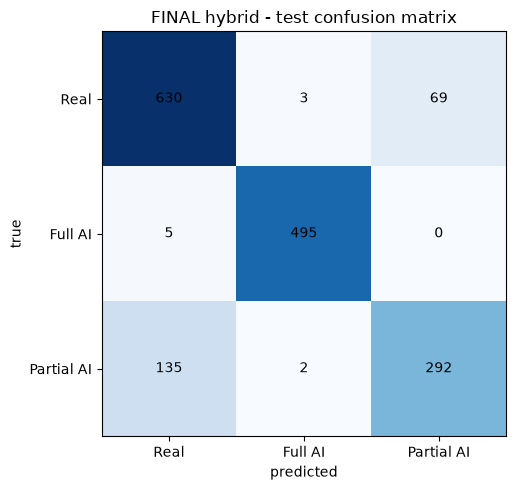

Saved: final_hybrid_deploy.pkl | results in C:\AI_Image_Project\results\unified
firstimg.jpeg: Real (71%) | Real 71.3% | Full AI 0.2% | Partial AI 28.4% | AI area = 0.00%


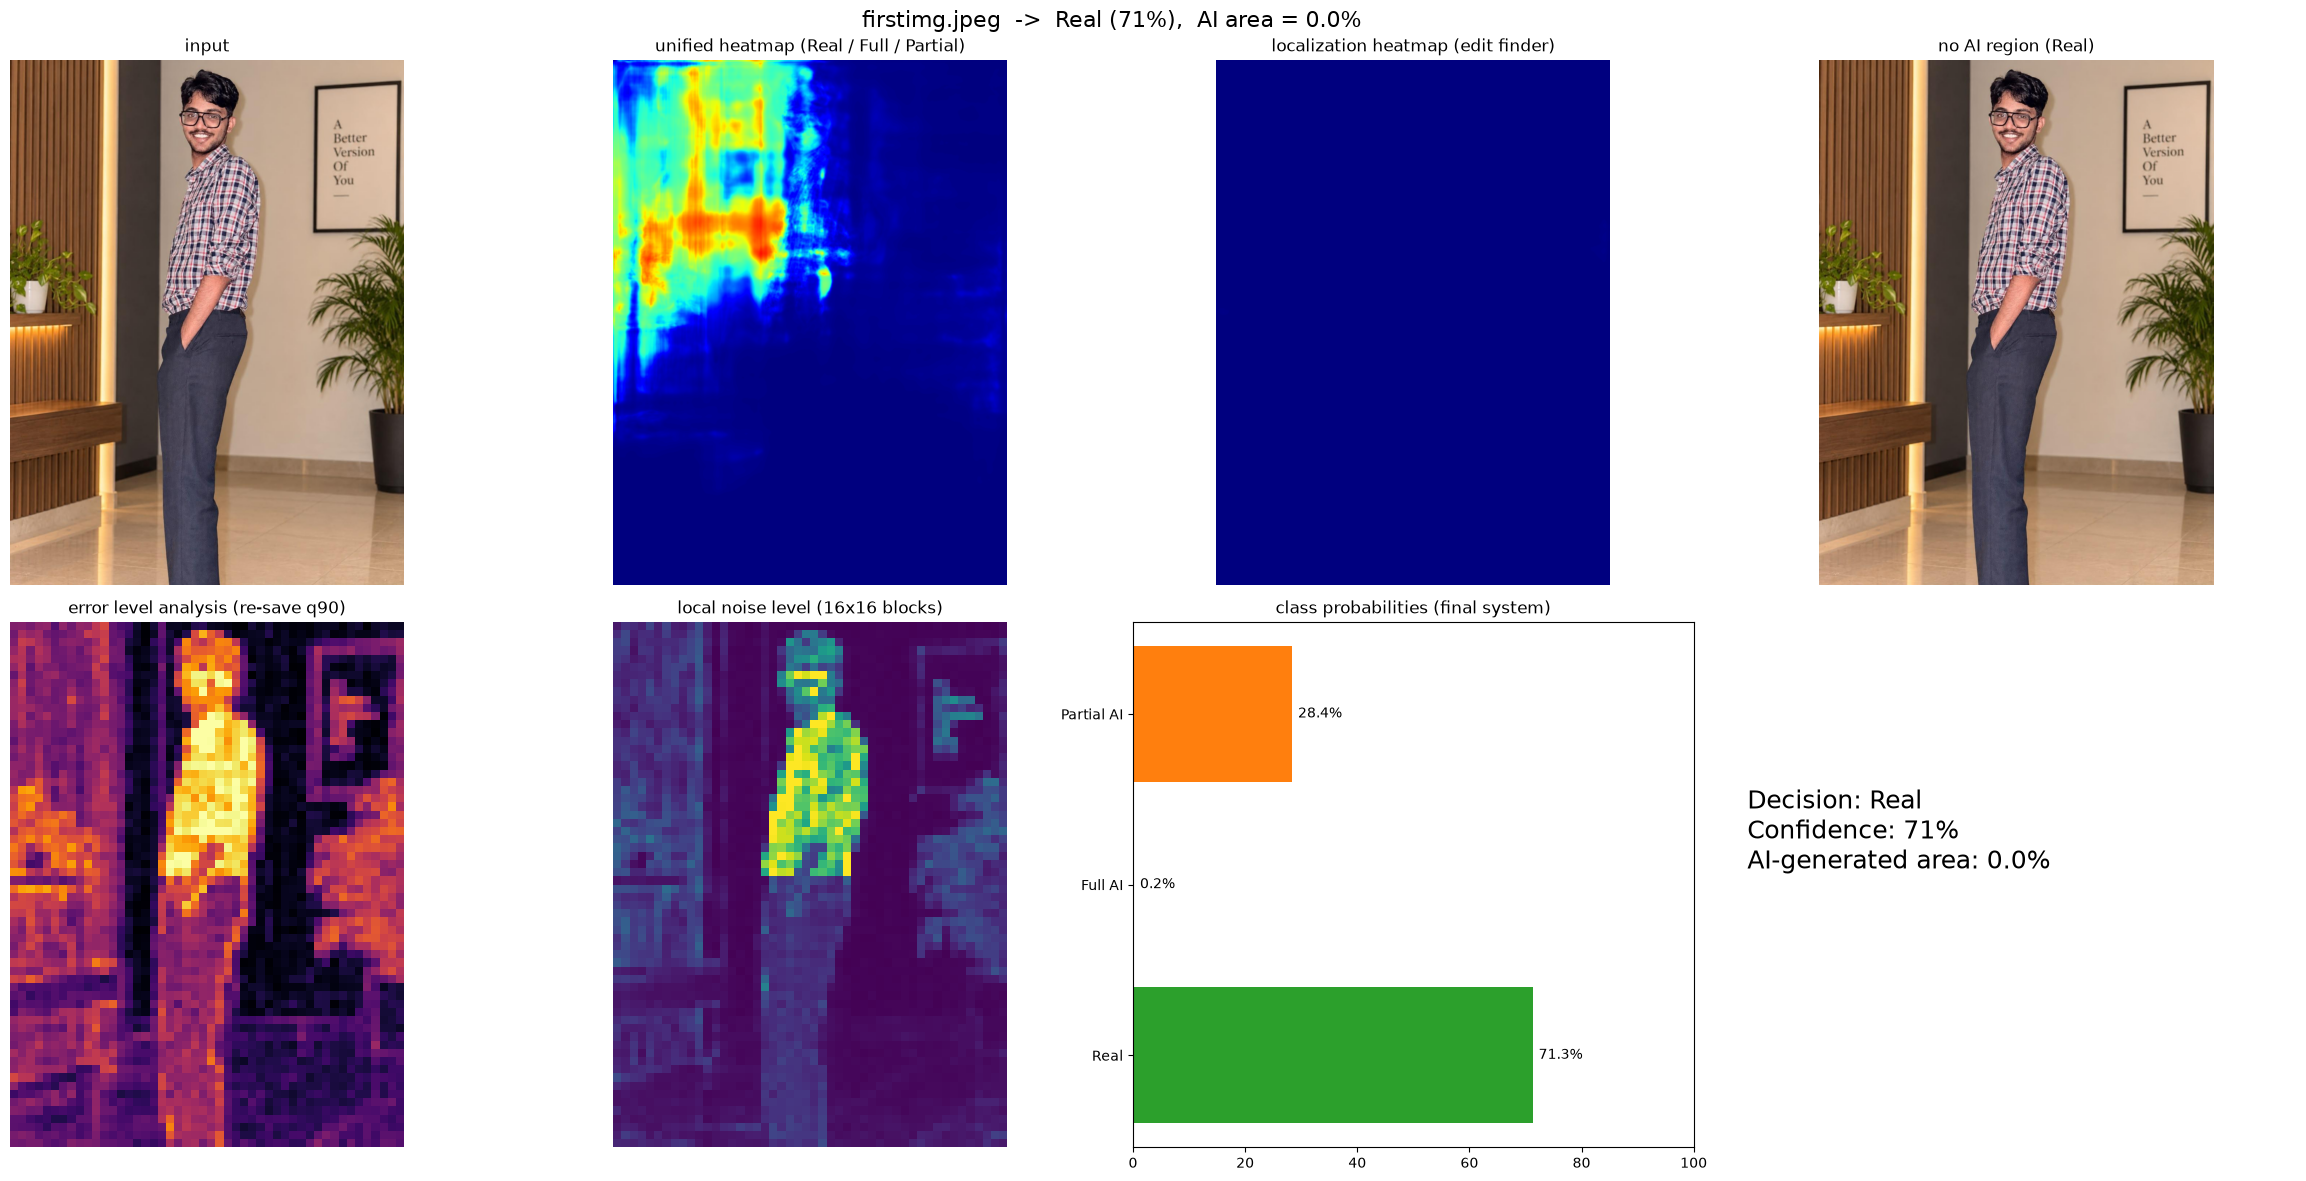

In [16]:

# ============================================================
# 8. Hybrid final system: unified model (class) + notebook-07 model (mask, area)
# ============================================================
LOC07 = "Unet_resnet34_crop512_plusbbox_clean"
d07 = torch.load(LOC_MODELS_DIR / f"{LOC07}_deploy.pth", map_location=device, weights_only=False)
model07 = smp.create_model(arch=d07["cfg"]["ARCH"], encoder_name=d07["cfg"]["ENCODER"], encoder_weights=None, in_channels=3, classes=1)
model07.load_state_dict(d07["model"]); model07 = model07.to(device).to(memory_format=torch.channels_last).eval()
T07 = int(np.argmin(np.abs(THRS - d07["threshold"])))                    # mask threshold validated in notebook 07
T07_AREA = int(np.argmin(np.abs(THRS - d07.get("mae_threshold", d07["threshold"]))))   # area threshold validated in notebook 07
model_u = make_model(); model_u.load_state_dict(torch.load(BEST, map_location=device, weights_only=False)["model"]); model_u.eval()

if "ev_val" not in globals() or "ev_test" not in globals():             # after a restart: recompute the unified pass
    ev_val = run_eval(model_u, DF[DF.split == "val"].reset_index(drop=True), tta=CFG["TTA"], desc="Unified - validation")
    ev_test = run_eval(model_u, DF[DF.split == "test"].reset_index(drop=True), tta=CFG["TTA"], desc="Unified - test")
e7_val = run_eval(model07, ev_val["df"], tta=True, desc="Model 07 - validation")
e7_test = run_eval(model07, ev_test["df"], tta=True, desc="Model 07 - test")
assert len(e7_val["label"]) == len(ev_val["label"]) and len(e7_test["label"]) == len(ev_test["label"])

Xv = np.hstack([ev_val["stats"], e7_val["stats"]]); Xt = np.hstack([ev_test["stats"], e7_test["stats"]])
HYB = make_clf().fit(Xv, ev_val["label"])
yt = ev_test["label"]; yp_h = HYB.predict(Xt); kinds = ev_test["df"].kind.to_numpy()
yp_u = CLF.predict(ev_test["stats"]) if "CLF" in globals() else make_clf().fit(ev_val["stats"], ev_val["label"]).predict(ev_test["stats"])

print("=" * 70); print("FINAL (hybrid) CLASSIFICATION - test"); print("=" * 70)
print(f"Accuracy {accuracy_score(yt, yp_h):.4f} | macro-F1 {f1_score(yt, yp_h, average='macro'):.4f}")
print(classification_report(yt, yp_h, target_names=CLASS_NAMES, digits=4))

f7_all, f7_segm = pixel_f1(e7_test, T07), pixel_f1(e7_test, T07, "segm")
area07 = 100 * e7_test["fracs"][:, T07_AREA]
pred_area = np.where(yp_h == 0, 0.0, np.where(yp_h == 1, 100.0, area07))
true_area = np.array([0.0 if l == 0 else 100.0 if l == 1 else (100 * e7_test["gt"][i] / e7_test["npx"][i] if e7_test["gt"][i] is not None else np.nan)
                      for i, l in enumerate(yt)])
ok = ~np.isnan(true_area); m2 = ok & (yt == 2); err = np.abs(pred_area - true_area); e_loc = np.abs(area07 - true_area)[m2]
print(f"Localization (07 model, threshold {THRS[T07]}): segm overall F1 {f7_segm[1]:.4f} | segm mean F1/image {f7_segm[0]:.4f} | all audited overall F1 {f7_all[1]:.4f}")
print(f"AI-area %: all test MAE {err[ok].mean():.2f} pp | Partial AI end-to-end MAE {err[m2].mean():.2f} pp | mask-only MAE {e_loc.mean():.2f} pp (median {np.median(e_loc):.2f})")

acc = lambda pred, k: accuracy_score(yt[kinds == k], pred[kinds == k]) if (kinds == k).any() else np.nan
fu_segm = pixel_f1(ev_test, int(np.nanargmax([pixel_f1(ev_val, t)[0] for t in range(len(THRS))])), "segm")
table = pd.DataFrame({
    "metric": ["3-class accuracy (this test set)", "Real (COCO) accuracy", "Real (originals) accuracy", "Full AI accuracy", "Partial AI accuracy",
               "Localization overall F1 (segm)", "Localization mean F1 per image (segm)", "Partial AI area MAE, mask only (pp)"],
    "earlier 07 + 09": [np.nan, 0.768, np.nan, 0.980, 0.788, 0.729, 0.547, 1.47],
    "unified only": [accuracy_score(yt, yp_u), acc(yp_u, "coco"), acc(yp_u, "original"), acc(yp_u, "diffusiondb"), acc(yp_u, "partial"),
                     fu_segm[1], fu_segm[0], np.nan],
    "FINAL hybrid": [accuracy_score(yt, yp_h), acc(yp_h, "coco"), acc(yp_h, "original"), acc(yp_h, "diffusiondb"), acc(yp_h, "partial"),
                     f7_segm[1], f7_segm[0], e_loc.mean()]})
print("\n" + "=" * 70); print("COMPARISON (earlier Partial AI accuracy came from a leaky random split)"); print("=" * 70)
print(table.round(3).to_string(index=False))
table.to_csv(OUT_DIR / "final_hybrid_comparison.csv", index=False)

cm = confusion_matrix(yt, yp_h, labels=range(3))
fig, ax = plt.subplots(figsize=(6, 5)); ax.imshow(cm, cmap="Blues")
ax.set_xticks(range(3), CLASS_NAMES); ax.set_yticks(range(3), CLASS_NAMES)
for (r_, c_), v in np.ndenumerate(cm): ax.text(c_, r_, v, ha="center", va="center")
ax.set_xlabel("predicted"); ax.set_ylabel("true"); ax.set_title("FINAL hybrid - test confusion matrix")
plt.tight_layout(); plt.savefig(OUT_DIR / "final_hybrid_confusion.png", dpi=110); plt.show()

FINAL_DEPLOY = LOC_MODELS_DIR / "final_hybrid_deploy.pkl"
pickle.dump({"classifier": HYB, "unified_run": RUN, "loc07_run": LOC07, "mask_t": float(THRS[T07]), "area_t": float(THRS[T07_AREA]),
             "cfg": CFG}, open(FINAL_DEPLOY, "wb"))
json.dump({"test_accuracy": float(accuracy_score(yt, yp_h)), "test_macro_f1": float(f1_score(yt, yp_h, average="macro")),
           "loc_f1_overall_segm": f7_segm[1], "loc_f1_per_image_segm": f7_segm[0], "area_mae_partial_mask_only": float(e_loc.mean()),
           "area_mae_all": float(err[ok].mean())}, open(OUT_DIR / "final_hybrid_summary.json", "w"), indent=2)
print("Saved:", FINAL_DEPLOY.name, "| results in", OUT_DIR)

# ---------------- analyse any image with the FINAL system ----------------
def forensic_maps(img, block=16, quality=90):
    rgb = img.convert("RGB"); a = np.asarray(rgb).astype(np.float32)
    b = io.BytesIO(); rgb.save(b, "JPEG", quality=quality); b.seek(0)
    ela = np.abs(a - np.asarray(Image.open(b).convert("RGB")).astype(np.float32)).mean(2)
    g = rgb.convert("L"); res = np.asarray(g).astype(np.float32) - np.asarray(g.filter(ImageFilter.MedianFilter(3))).astype(np.float32)
    H, W = (ela.shape[0] // block) * block, (ela.shape[1] // block) * block
    blk = lambda m, f: f(m[:H, :W].reshape(H // block, block, W // block, block), axis=(1, 3))
    return blk(ela, np.mean), blk(res, np.std)

REPORT_DIR = PROJECT_DIR / "results" / "analysis"; REPORT_DIR.mkdir(parents=True, exist_ok=True)
def analyze_final(path, show=True, save=True):
    img = ImageOps.exif_transpose(Image.open(path)).convert("RGB")
    s = min(1.0, CFG["MAX_SIDE"] / max(img.size))
    if s < 1: img = img.resize((round(img.size[0] * s), round(img.size[1] * s)), Image.Resampling.BICUBIC)
    arr = np.asarray(img)
    pu = predict_prob(model_u, arr, CFG["TTA"]); p7 = predict_prob(model07, arr, True)
    probs = HYB.predict_proba(np.hstack([image_stats(pu), image_stats(p7)])[None])[0]; cls = int(np.argmax(probs))
    h7 = p7.cpu().numpy(); hu = pu.cpu().numpy(); mask = h7 >= THRS[T07]
    area = 0.0 if cls == 0 else 100.0 if cls == 1 else 100 * float((h7 >= THRS[T07_AREA]).mean())
    print(f"{Path(path).name}: {CLASS_NAMES[cls]} ({probs[cls]*100:.0f}%) | " + " | ".join(f"{n} {q*100:.1f}%" for n, q in zip(CLASS_NAMES, probs))
          + f" | AI area = {area:.2f}%")
    if show or save:
        ela, noise = forensic_maps(img)
        ov = arr.copy()
        if cls == 2: ov[mask] = (0.5 * ov[mask] + [127, 0, 0]).astype(np.uint8)
        elif cls == 1: ov = (0.5 * ov + [127, 0, 0]).astype(np.uint8)
        fig, ax = plt.subplots(2, 4, figsize=(24, 12))
        ax[0, 0].imshow(arr); ax[0, 0].set_title("input")
        ax[0, 1].imshow(hu, cmap="jet", vmin=0, vmax=1); ax[0, 1].set_title("unified heatmap (Real / Full / Partial)")
        ax[0, 2].imshow(h7, cmap="jet", vmin=0, vmax=1); ax[0, 2].set_title("localization heatmap (edit finder)")
        ax[0, 3].imshow(ov); ax[0, 3].set_title({0: "no AI region (Real)", 1: "whole image AI (Full AI)", 2: f"edited region: {area:.1f}% of image"}[cls])
        ax[1, 0].imshow(ela, cmap="inferno", vmax=np.percentile(ela, 99)); ax[1, 0].set_title("error level analysis (re-save q90)")
        ax[1, 1].imshow(noise, cmap="viridis", vmax=np.percentile(noise, 99)); ax[1, 1].set_title("local noise level (16x16 blocks)")
        ax[1, 2].barh(CLASS_NAMES, probs * 100, color=["#2ca02c", "#d62728", "#ff7f0e"]); ax[1, 2].set_xlim(0, 100)
        for k_, q_ in enumerate(probs): ax[1, 2].text(min(q_ * 100 + 1, 85), k_, f"{q_*100:.1f}%", va="center")
        ax[1, 2].set_title("class probabilities (final system)")
        ax[1, 3].axis("off"); ax[1, 3].text(0.02, 0.6, f"Decision: {CLASS_NAMES[cls]}\nConfidence: {probs[cls]*100:.0f}%\nAI-generated area: {area:.1f}%",
                                           fontsize=18, va="center")
        for x_ in [ax[0, 0], ax[0, 1], ax[0, 2], ax[0, 3], ax[1, 0], ax[1, 1]]: x_.axis("off")
        plt.suptitle(f"{Path(path).name}  ->  {CLASS_NAMES[cls]} ({probs[cls]*100:.0f}%),  AI area = {area:.1f}%", fontsize=16); plt.tight_layout()
        if save: plt.savefig(REPORT_DIR / f"{Path(path).stem}_final.png", dpi=90)
        plt.show() if show else plt.close(fig)
    return {"class": CLASS_NAMES[cls], "probs": probs, "ai_area_pct": area}

if IN_COLAB:
    from google.colab import files
    for name in files.upload(): analyze_final(name)
else:
    analyze_final(r"C:\Users\gopic\Downloads\firstimg.jpeg")
